# XGBoost · FinX model (Owen)

**Target:** `target_next_ret` = next-day S&P 500 return
**Input:** the last 5 trading days of all 58 input columns (index return, VIX and VIX change, 50 stocks, indicators), flattened into 5 x 58 = 290 features. The window is built only by the shared `make_window`; no private lags.
**Validation:** the shared walk-forward harness (`walk_forward` in `src/finx_common.py`), same 3 folds as every FinX model.

| Fold | Train | Test |
|---|---|---|
| 1 | 2021-01-04 to 2023 | 2024 |
| 2 | 2021-01-04 to 2024 | 2025 |
| 3 | 2021-01-04 to 2025 | 2026 to 21 Sep |

**Settings (fixed in advance, no grid search, no tuning on test years):** `XGBRegressor` with max_depth 3, learning_rate 0.03,
up to 500 trees, subsample 0.8, colsample_bytree 0.3, seed 42, CPU only. Early stopping with `early_stopping_rounds=30` on the
validation slice = the last 10% of the training rows (in time order, no shuffling). The model is trained once per fold and
never retrained afterwards. Trees need no scaling, so none is used. Code: `models/xgboost_model.py`.

**Outputs:** `outputs/preds_xgboost.csv` and `outputs/timing_xgboost.json` (written by the harness);
`outputs/xgboost/xgboost_folds.csv`, `outputs/xgboost/xgboost_scores.csv` and `outputs/xgboost/fig_xgboost_feature_importance.png`.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "src"), str(ROOT / "models")]
import config as C
import xgboost_model as X                 # fit / predict / NAME
from finx_common import FOLDS, fold_split, load_master, make_window, score, walk_forward

warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 160)
OUT = C.OUT_DIR / "xgboost"
OUT.mkdir(parents=True, exist_ok=True)

## 2. Load the frozen master and check the input shape

In [2]:
master = load_master()                 # checksum and row count are checked on load
print(f"{len(master)} trading days: {master.index.min().date()} to {master.index.max().date()}")

Xall, yall = make_window(master)
feature_names = list(Xall.columns)
assert master.shape[1] - 1 == C.EXPECTED_N_FEATURES == 58
assert Xall.shape[1] == 290 == C.WINDOW * 58, Xall.shape
assert len(FOLDS) == 3
print(f"Window table: {Xall.shape[0]} rows x {Xall.shape[1]} features (5 days x 58 columns); "
      f"example columns: {feature_names[:2]} ... {feature_names[-1]}")

1435 trading days: 2021-01-04 to 2026-09-21
Window table: 1431 rows x 290 features (5 days x 58 columns); example columns: ['ret_index_lag0', 'AAPL_ret_lag0'] ... hl_range_lag4


## 3. Walk-forward run (shared harness)
`walk_forward` is called once. It fits once per fold, predicts every test day, times training and the latency of one
next-day prediction, and writes `preds_xgboost.csv` and `timing_xgboost.json`. The wrapper only keeps each fold's fitted
model so the next sections can report the number of trees and the feature importance without refitting.

In [3]:
fitted = []

def fit_and_keep(train):
    m = X.fit(train)
    fitted.append(m)
    return m

P, timing = walk_forward(fit_and_keep, X.predict, X.NAME, df=master)

[xgboost] fold 2024: train 753 days, test 252 days, train 0.1s, 12.233 ms for one prediction


[xgboost] fold 2025: train 1005 days, test 250 days, train 0.1s, 12.185 ms for one prediction


[xgboost] fold 2026: train 1255 days, test 180 days, train 0.1s, 14.103 ms for one prediction


In [4]:
# Checks that the run matches the spec
n_test = sum(len(fold_split(master, f)[1]) for f in FOLDS)
assert len(fitted) == 3
assert len(P) == n_test, (len(P), n_test)
assert P["pred"].notna().all()
for m in fitted:
    p = m.get_params()
    assert p["early_stopping_rounds"] == 30
    assert (p["max_depth"], p["learning_rate"], p["n_estimators"]) == (3, 0.03, 500)
    assert (p["subsample"], p["colsample_bytree"], p["random_state"]) == (0.8, 0.3, C.SEED)
    assert m.n_features_in_ == 290
print(f"{len(P)} pooled predictions over {len(fitted)} folds; early_stopping_rounds = 30 in every fold.")

682 pooled predictions over 3 folds; early_stopping_rounds = 30 in every fold.


## 4. Trees used per fold
Early stopping halts when the validation error has not improved for 30 rounds; `best_iteration` is the index of the best
round (0-based), so the model keeps `best_iteration + 1` trees. If it equals 499 the 500-tree cap was reached first.

In [5]:
rows = []
for fold, m in zip(FOLDS, fitted):
    train = fold_split(master, fold)[0]
    Xf, _ = make_window(train)
    k = int(len(Xf) * (1 - C.VAL_FRACTION))
    rows.append({"test_year": fold[0], "train_days": len(train), "window_rows": len(Xf),
                 "fit_rows": k, "validation_rows": len(Xf) - k, "n_features": m.n_features_in_,
                 "best_iteration": int(m.best_iteration), "trees_kept": int(m.best_iteration) + 1,
                 "hit_500_cap": int(m.best_iteration) >= 499,
                 "train_s": round(timing["train_s"][fold[0]], 2)})
folds = pd.DataFrame(rows)
folds.to_csv(OUT / "xgboost_folds.csv", index=False)
folds

,test_year,train_days,window_rows,fit_rows,validation_rows,n_features,best_iteration,trees_kept,hit_500_cap,train_s
0,2024,753,749,674,75,290,4,5,False,0.10
1,2025,1005,1001,900,101,290,8,9,False,0.09
2,2026,1255,1251,1125,126,290,3,4,False,0.09


## 5. Feature importance (last fold)
Top 15 of the 290 inputs for the model trained on 2021 to 2025 (the fold that tests 2026). Importance is the model's own
`feature_importances_` (XGBoost default, gain-based, summing to 1 over all 290 inputs). Each label is
`column (day)`: `t` = the day the prediction is made (close of day t), `t-1` = the day before, up to `t-4`.

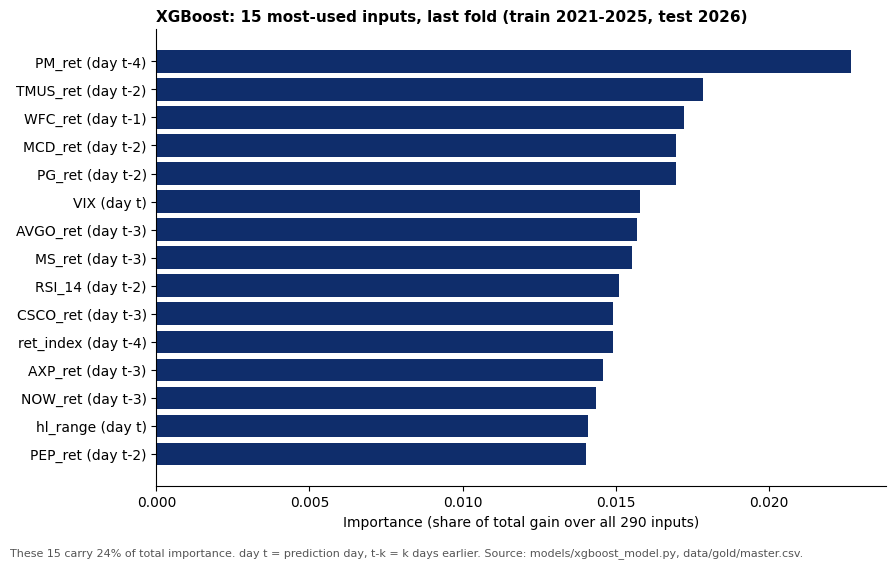

,feature,label,importance
0,PM_ret_lag4,PM_ret (day t-4),0.0227
1,TMUS_ret_lag2,TMUS_ret (day t-2),0.0179
2,WFC_ret_lag1,WFC_ret (day t-1),0.0173
3,MCD_ret_lag2,MCD_ret (day t-2),0.0170
4,PG_ret_lag2,PG_ret (day t-2),0.0170
5,VIX_lag0,VIX (day t),0.0158
6,AVGO_ret_lag3,AVGO_ret (day t-3),0.0157
7,MS_ret_lag3,MS_ret (day t-3),0.0155
8,RSI_14_lag2,RSI_14 (day t-2),0.0151
9,CSCO_ret_lag3,CSCO_ret (day t-3),0.0149


In [6]:
last = fitted[-1]
assert last.n_features_in_ == len(feature_names)

def pretty(name):
    col, lag = name.rsplit("_lag", 1)
    return f"{col} (day {'t' if lag == '0' else 't-' + lag})"

imp = pd.Series(last.feature_importances_, index=feature_names)
top = imp.nlargest(15)
top_tbl = pd.DataFrame({"feature": top.index, "label": [pretty(n) for n in top.index], "importance": top.values.round(4)})
top_tbl.to_csv(OUT / "xgboost_top15_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh([pretty(n) for n in top.index][::-1], top.values[::-1], color="#0f2d6b")
ax.set_xlabel("Importance (share of total gain over all 290 inputs)")
ax.set_title(f"XGBoost: 15 most-used inputs, last fold (train 2021-{int(FOLDS[-1][0]) - 1}, test {FOLDS[-1][0]})",
             fontsize=11, fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, f"These 15 carry {top.sum():.0%} of total importance. day t = prediction day, t-k = k days earlier. "
         "Source: models/xgboost_model.py, data/gold/master.csv.", fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(OUT / "fig_xgboost_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
top_tbl

## 6. Scores
All test days pooled (not averaged per fold), then each fold. Naive = always predict 0, so naive RMSE = sqrt(mean(actual^2)).
Skill vs naive = 1 - RMSE(model) / RMSE(naive). "Always up (%)" is the share of days the market rose, the direction
benchmark. "Forecast up (%)" is the share of days XGBoost predicted a positive return.

In [7]:
def row(g, label):
    a = g["actual"]
    s = score(a, g["pred"], float(np.sqrt((a ** 2).mean())))
    up = 100 * (a[a != 0] > 0).mean()
    return {"test days": label, "n": len(g), "RMSE (%)": s["RMSE"] * 100, "MAE (%)": s["MAE"] * 100,
            "Direction (%)": s["Direction %"], "Always up (%)": up,
            "Skill vs naive (%)": s["Skill vs naive"] * 100, "Forecast up (%)": 100 * (g["pred"] > 0).mean()}

scores = pd.DataFrame([row(P, "pooled")] + [row(g, str(f)) for f, g in P.groupby("fold")]).round(3)
scores.to_csv(OUT / "xgboost_scores.csv", index=False)
t = {k: float(np.mean(list(v.values()))) for k, v in timing.items() if k != "hardware"}
print(f"Train time per fold: {t['train_s']:.2f} s   Inference per day: {t['latency_ms_per_day']:.2f} ms   "
      f"Hardware: {timing['hardware']}")
scores

Train time per fold: 0.09 s   Inference per day: 12.84 ms   Hardware: {'cpu': 'arm', 'cores': 11, 'gpu': 'none'}


,test days,n,RMSE (%),MAE (%),Direction (%),Always up (%),Skill vs naive (%),Forecast up (%)
0,pooled,682,0.962,0.655,54.985,56.012,0.387,94.868
1,2024,252,0.797,0.590,55.556,56.746,0.282,95.635
2,2025,250,1.175,0.729,58.000,58.000,0.471,92.800
3,2026,180,0.837,0.642,50.000,52.222,0.292,96.667


## 7. Notes for the group chat
Three lines, each quoting a number from the scores table above. The cell below fills the numbers from the computed
results; the verdict words (better/worse, above/below) are also computed. Replace each `[reason: ...]` with a short
explanation only after looking at the outputs (for example the fold table, the importance chart, or the forecast-up share).
Do not tune on the test years to change these numbers.

In [8]:
s = scores.iloc[0]
f = scores.iloc[1:].set_index("test days")
better = lambda x: "better" if x > 0 else "worse"
best_fold, worst_fold = f["Skill vs naive (%)"].idxmax(), f["Skill vs naive (%)"].idxmin()
print(f"1. RMSE: XGBoost {s['RMSE (%)']:.3f}% vs naive {100 * np.sqrt((P['actual'] ** 2).mean()):.3f}% "
      f"(skill {s['Skill vs naive (%)']:+.2f}%), so {better(s['Skill vs naive (%)'])} than naive on all {int(s['n'])} days. [reason: ...]")
print(f"2. Direction: {s['Direction (%)']:.1f}% vs always-up {s['Always up (%)']:.1f}%, "
      f"{'above' if s['Direction (%)'] > s['Always up (%)'] else 'not above'} the benchmark; "
      f"XGBoost forecast up on {s['Forecast up (%)']:.1f}% of days. [reason: ...]")
print(f"3. By fold: skill vs naive is best in {best_fold} ({f.loc[best_fold, 'Skill vs naive (%)']:+.2f}%) "
      f"and worst in {worst_fold} ({f.loc[worst_fold, 'Skill vs naive (%)']:+.2f}%); "
      f"trees kept per fold: {', '.join(str(n) for n in folds['trees_kept'])}. [reason: ...]")

1. RMSE: XGBoost 0.962% vs naive 0.966% (skill +0.39%), so better than naive on all 682 days. [reason: ...]
2. Direction: 55.0% vs always-up 56.0%, not above the benchmark; XGBoost forecast up on 94.9% of days. [reason: ...]
3. By fold: skill vs naive is best in 2025 (+0.47%) and worst in 2024 (+0.28%); trees kept per fold: 5, 9, 4. [reason: ...]


In [9]:
s = scores.iloc[0]
print(f"XGBoost (all {int(s['n'])} test days): RMSE {s['RMSE (%)']:.3f}%  MAE {s['MAE (%)']:.3f}%  "
      f"Direction {s['Direction (%)']:.1f}%  Skill vs naive {s['Skill vs naive (%)']:+.2f}%")
print(f"Train {t['train_s']:.2f} s per fold  |  Inference {t['latency_ms_per_day']:.2f} ms per day  |  "
      f"Hardware: {timing['hardware']['cpu']}, {timing['hardware']['cores']} cores, GPU {timing['hardware']['gpu']}")

XGBoost (all 682 test days): RMSE 0.962%  MAE 0.655%  Direction 55.0%  Skill vs naive +0.39%
Train 0.09 s per fold  |  Inference 12.84 ms per day  |  Hardware: arm, 11 cores, GPU none
